## 1. Import libraries 

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv(r'E:\python hw\kì 4\bs140513_032310.csv')
df.head(5)

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


## 2. EDA

In [25]:
df.nunique()

step             180
customer        4112
age                8
gender             4
zipcodeOri         1
merchant          50
zipMerchant        1
category          15
amount         23767
fraud              2
dtype: int64

In [26]:
df['gender'].value_counts()

gender
'F'    324565
'M'    268385
'E'      1178
'U'       515
Name: count, dtype: int64

In [27]:
df = df.drop(['zipcodeOri','zipMerchant'], axis = 1)
df.head()

,step,customer,age,gender,merchant,category,amount,fraud
0,0,'C1093826151','4','M','M348934600','es_transportation',4.55,0
1,0,'C352968107','2','M','M348934600','es_transportation',39.68,0
2,0,'C2054744914','4','F','M1823072687','es_transportation',26.89,0
3,0,'C1760612790','3','M','M348934600','es_transportation',17.25,0
4,0,'C757503768','5','M','M348934600','es_transportation',35.72,0


In [28]:
df_fraud = df.loc[df.fraud == 1] 
df_non_fraud = df.loc[df.fraud == 0]

In [29]:
df_fraud.head()

,step,customer,age,gender,merchant,category,amount,fraud
88,0,'C583110837','3','M','M480139044','es_health',44.26,1
89,0,'C1332295774','3','M','M480139044','es_health',324.50,1
434,0,'C1160421902','3','M','M857378720','es_hotelservices',176.32,1
435,0,'C966214713','3','M','M857378720','es_hotelservices',337.41,1
553,0,'C1450140987','4','F','M1198415165','es_wellnessandbeauty',220.11,1


In [30]:
df_non_fraud.head()

,step,customer,age,gender,merchant,category,amount,fraud
0,0,'C1093826151','4','M','M348934600','es_transportation',4.55,0
1,0,'C352968107','2','M','M348934600','es_transportation',39.68,0
2,0,'C2054744914','4','F','M1823072687','es_transportation',26.89,0
3,0,'C1760612790','3','M','M348934600','es_transportation',17.25,0
4,0,'C757503768','5','M','M348934600','es_transportation',35.72,0


In [31]:
def edaplot(data: pd.DataFrame, col: str, title: str = None, hue: str = None, legend: bool = True):
    plt.figure(figsize=(17, 14))
    plt.title(title)
    ax = sns.countplot(
        data = data,
        x = col,
        palette = 'tab10',
        order = data[col].value_counts().index,
        hue = hue if hue else None
    )

    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.text(p.get_x() + p.get_width() / 2.0, height + 3,
                    f"{round(100 * height / len(data[col]), 2)}%",
                    ha = 'center', va = 'bottom')

    if legend:
        ax.legend(title=hue)

    plt.show()

C:\Users\Acer\AppData\Local\Temp\ipykernel_22896\233721992.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(
C:\Users\Acer\AppData\Local\Temp\ipykernel_22896\233721992.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=hue)


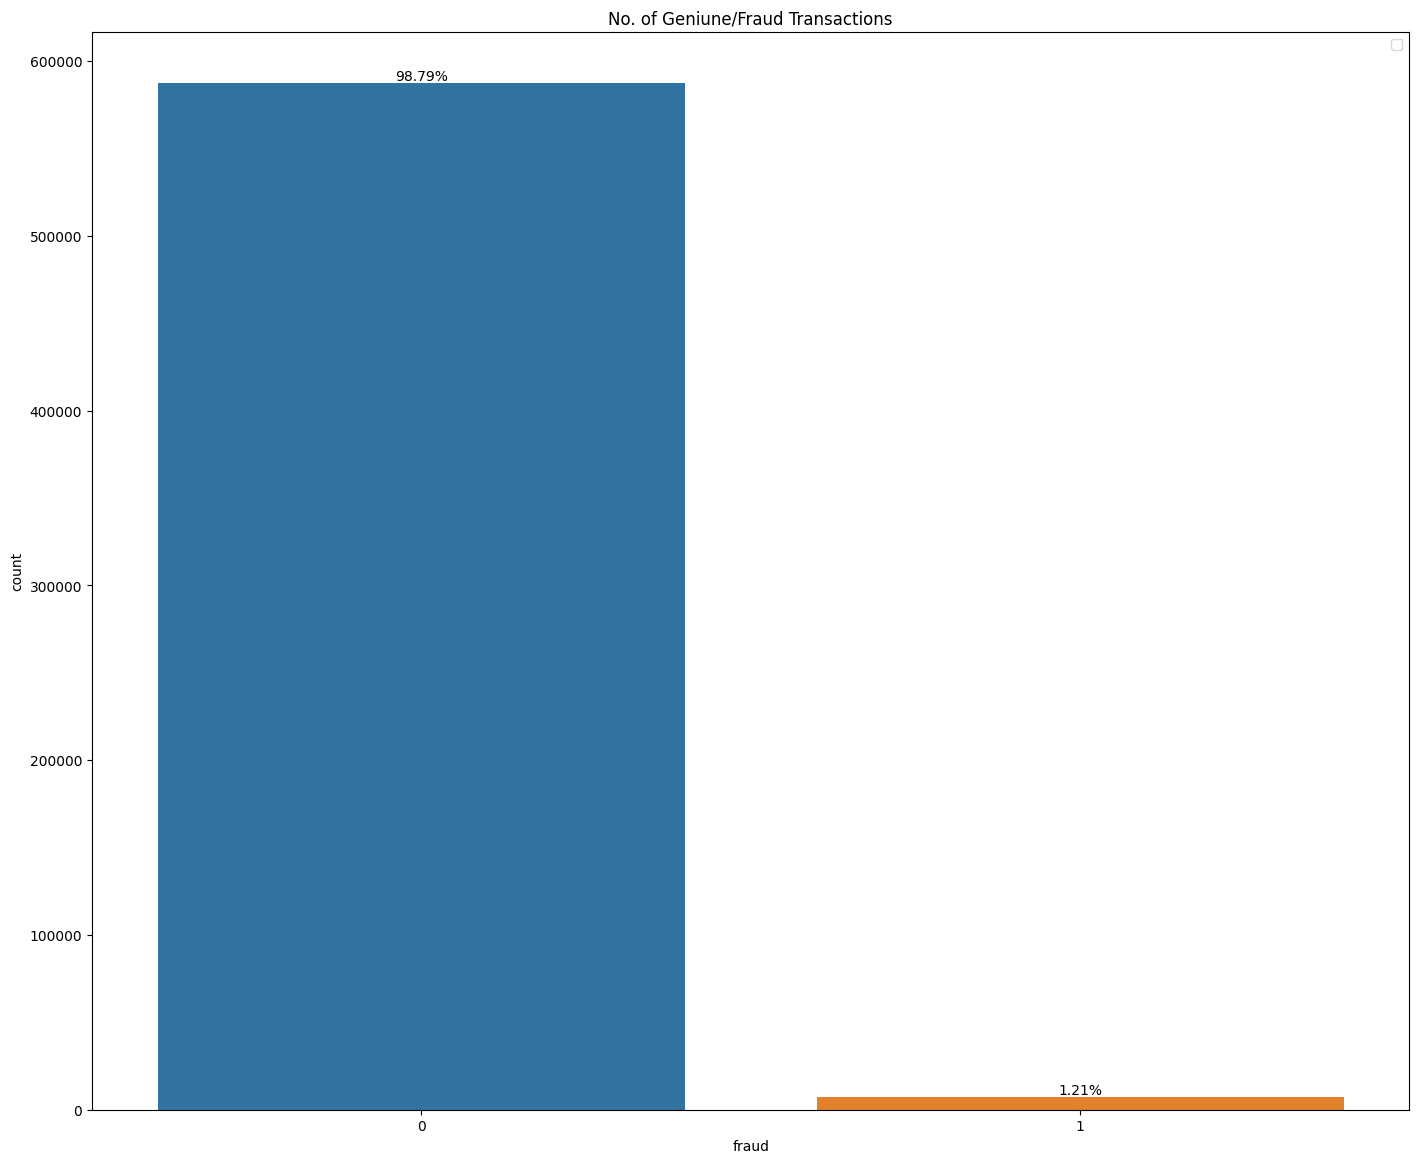

In [32]:
edaplot(df, 'fraud', title = 'No. of Geniune/Fraud Transactions', legend=True)

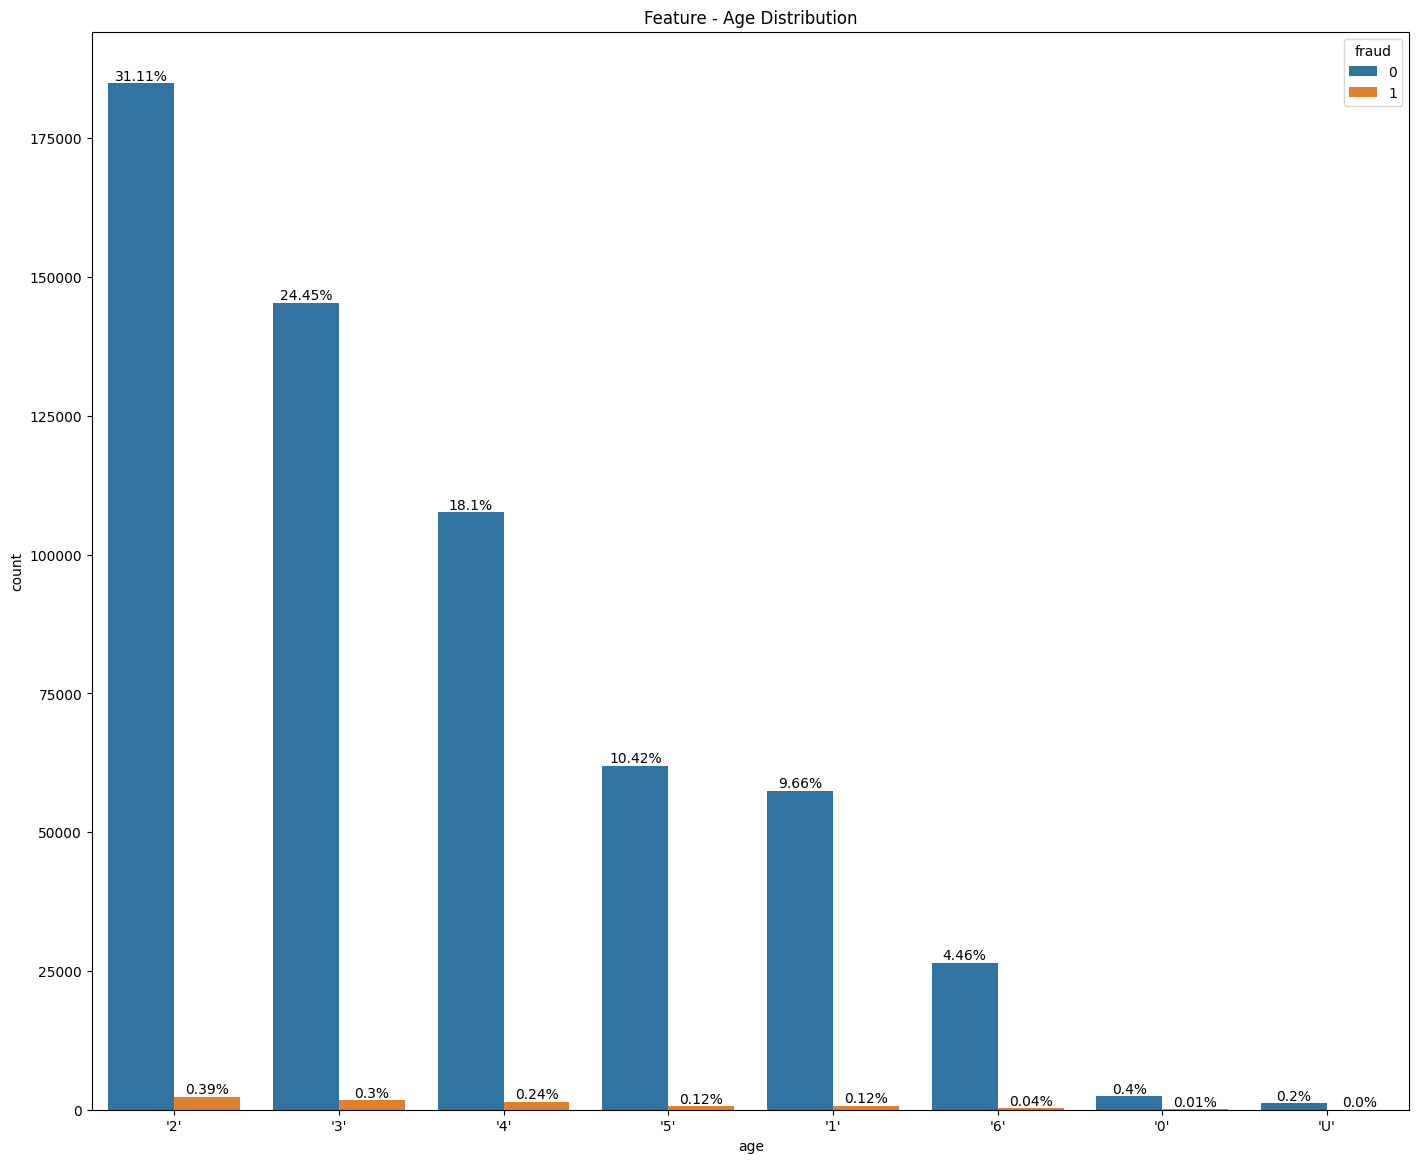

In [33]:
edaplot(df, 'age', title = 'Feature - Age Distribution', hue = 'fraud')

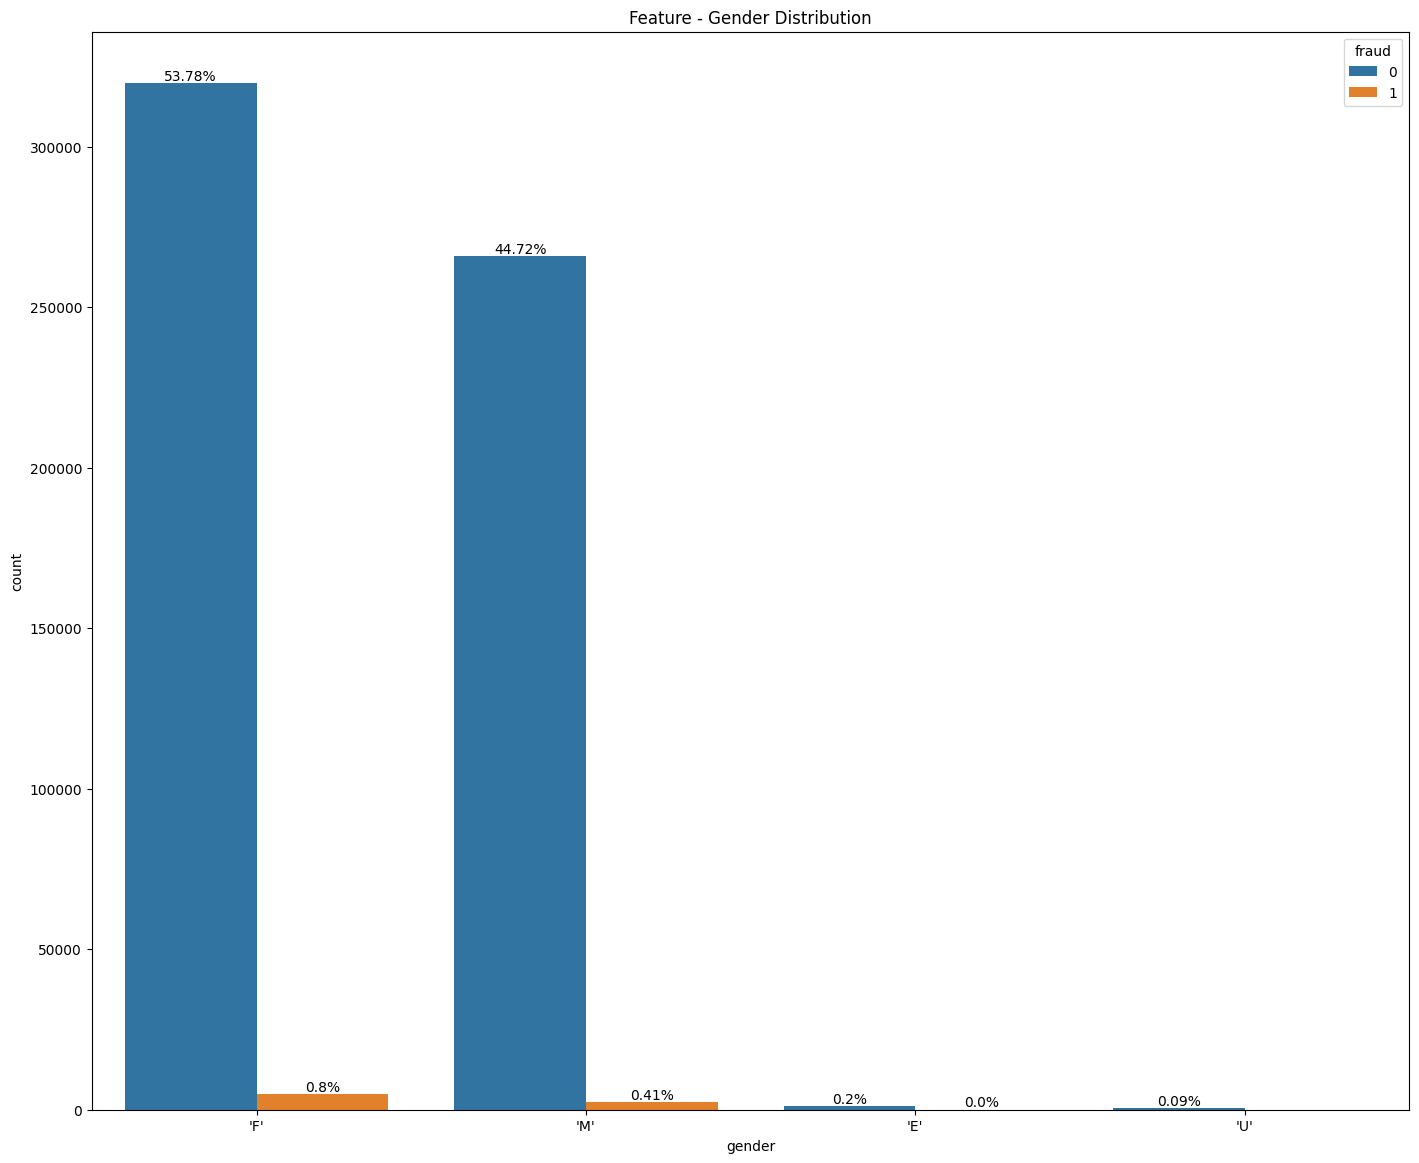

In [34]:
edaplot(df, 'gender', title = 'Feature - Gender Distribution', hue = 'fraud')

In [35]:
print(df['category'].unique())

["'es_transportation'" "'es_health'" "'es_otherservices'" "'es_food'"
 "'es_hotelservices'" "'es_barsandrestaurants'" "'es_tech'"
 "'es_sportsandtoys'" "'es_wellnessandbeauty'" "'es_hyper'" "'es_fashion'"
 "'es_home'" "'es_contents'" "'es_travel'" "'es_leisure'"]


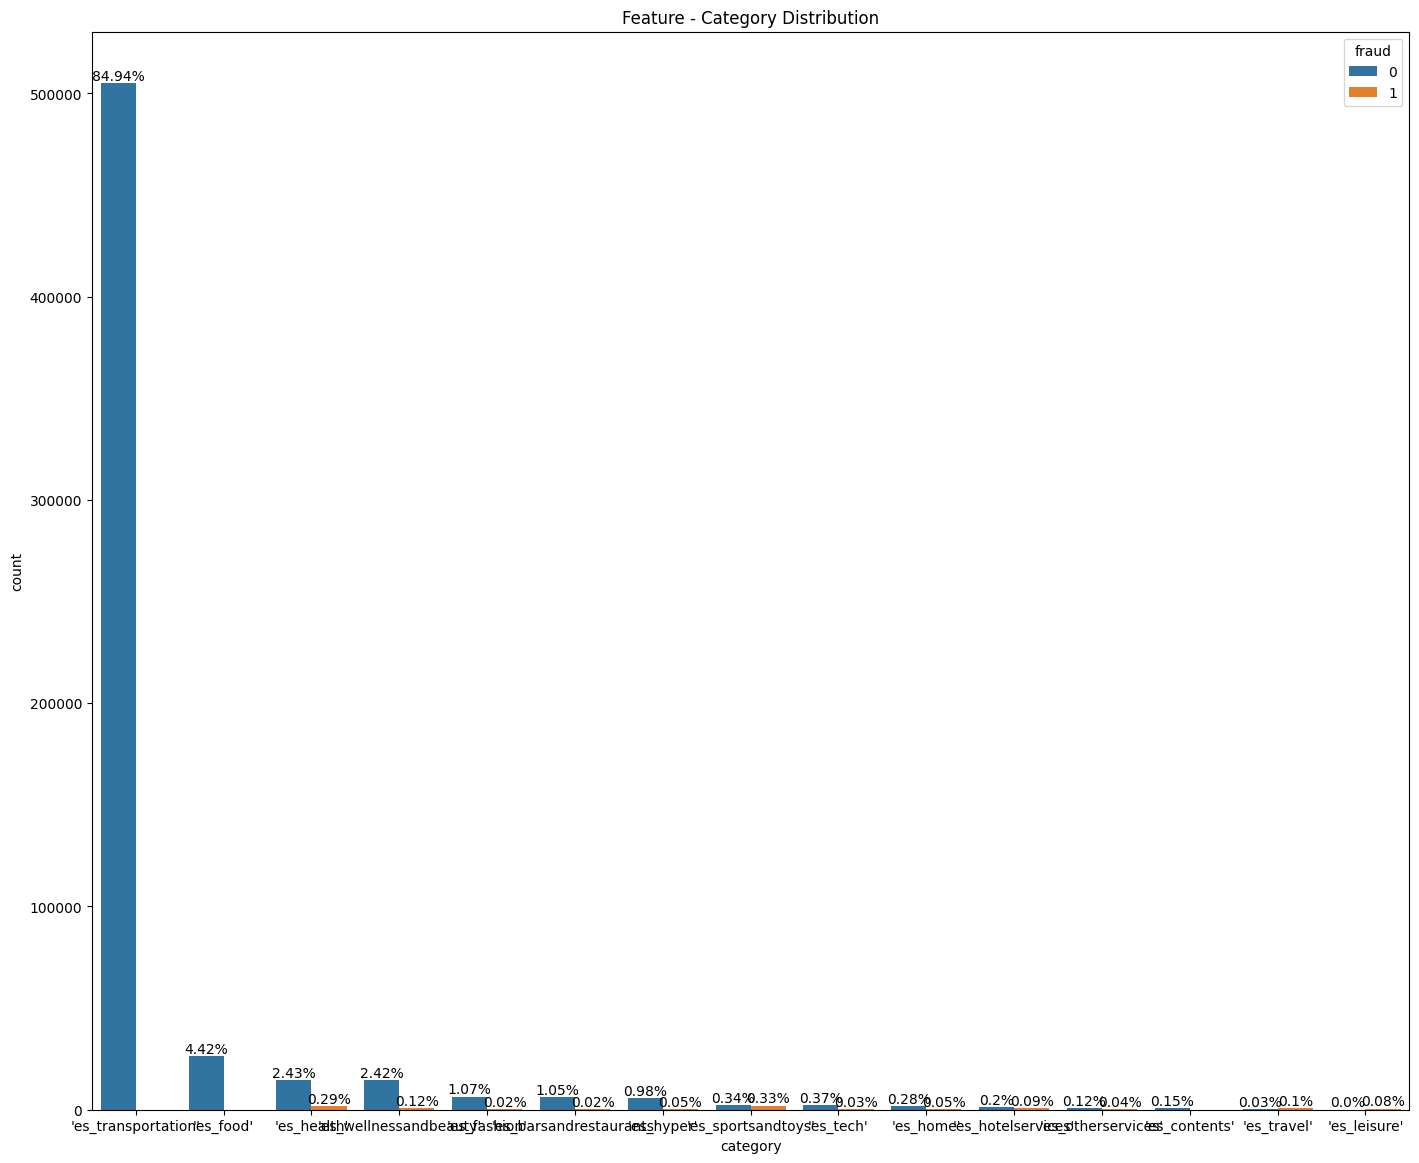

In [36]:
edaplot(df, 'category', title = 'Feature - Category Distribution', hue = 'fraud')

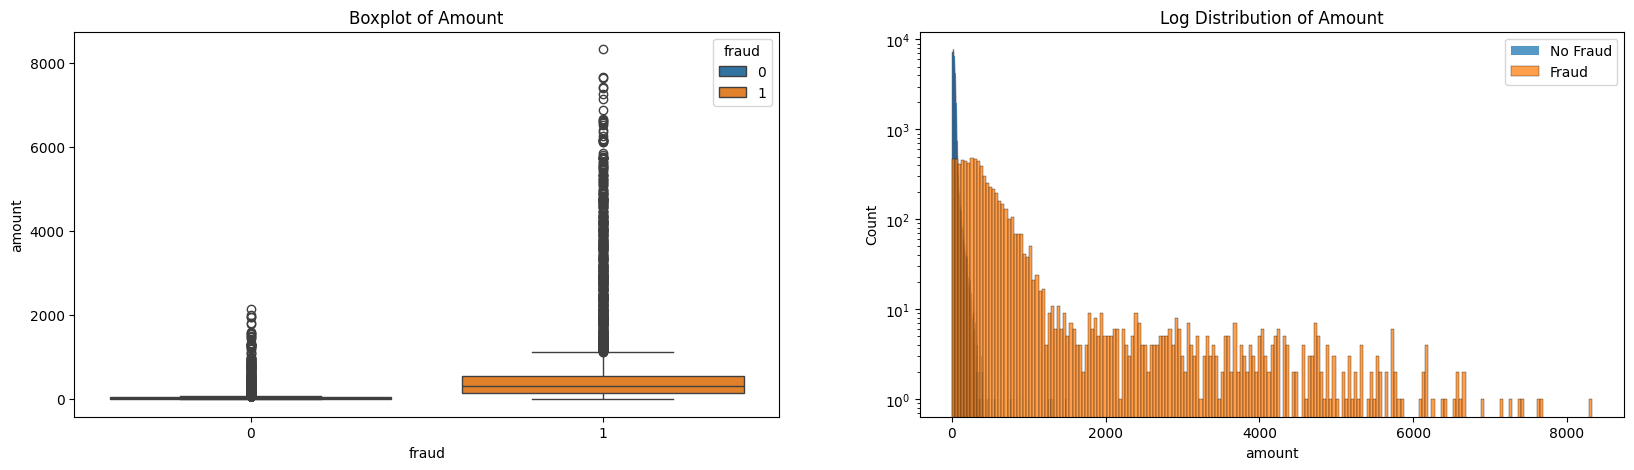

In [37]:
fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize = (20, 5))
ax1.set_title('Boxplot of Amount')
sns.boxplot(data = df, x = 'fraud', y = 'amount', hue = 'fraud', ax = ax1)

ax2.set_title('Log Distribution of Amount')
sns.histplot(df[df['fraud'] == 0]['amount'], label = 'No Fraud', ax = ax2)
sns.histplot(df[df['fraud'] == 1]['amount'], label = 'Fraud', ax = ax2)
ax2.set_yscale('log')
ax2.legend()
plt.show()

In [39]:
print('     Fraudulent Transaction:')
print(f"Maximun amount of transaction: {df[df['fraud'] == 1]['amount'].max()}")
print(f"Minimum amount of transaction: {df[df['fraud'] == 1]['amount'].min()}")
print(f"Average amount of transaction: {df[df['fraud'] == 1]['amount'].mean()}")

print('\n   Non-Fraudulent Transaction:')
print(f"Maximun amount of transaction: {df[df['fraud'] == 0]['amount'].max()}")
print(f"Minimum amount of transaction: {df[df['fraud'] == 0]['amount'].min()}")
print(f"Average amount of transaction: {df[df['fraud'] == 0]['amount'].mean()}")

     Fraudulent Transaction:
Maximun amount of transaction: 8329.96
Minimum amount of transaction: 0.03
Average amount of transaction: 530.9265513888889

   Non-Fraudulent Transaction:
Maximun amount of transaction: 2144.86
Minimum amount of transaction: 0.0
Average amount of transaction: 31.847230386607713
